# 2013TSA Cohort Replication

- Do predefined 2013TSA associations recur in the independent 2024TSA Labrador cohort?
- GMMAT and GEMMA test retained measured targets in Scheme A and Scheme B, with sex and relatedness adjustment.
- Association tests estimate evidence at historical targets; simulations assess false-positive rates and detection power under specified assumptions.
- These methods do not establish causality; directional replication also requires matching historical alleles and effect definitions.

### Labrador Comparisons
- Scheme A is primary.
- Scheme B adds two controls and shares all seven cases.
- Models adjust for recorded sex, specified before inspecting associations.

| Scheme | Controls | Behavioral Cases | Dogs |
| :---: | :---: | :---: | :---: |
| A | 39 | 7 | 46 |
| B | 41 | 7 | 48 |

### (Initialization) Import Directory-Free Helpers
### (Parse) Load Measured Targets
- Preparation checks measured calls against an independent PLINK export.
- Saved results retain the target inventory.
- *prepare_replication.py*

In [1]:
# Locate the repository and prepare historical targets only when the preparation manifest is absent.
# Check independent genotype verification and the alignment hash before reviewing retained targets.

from pathlib import Path
import importlib
import sys

study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/notebook_support.py").exists())
sys.path.insert(0, str(study_root / "scripts"))
read_json = importlib.import_module("notebook_support").read_json
file_digest = importlib.import_module("notebook_support").file_digest
require_saved = importlib.import_module("notebook_review").require_saved
run_script = importlib.import_module("notebook_support").run_script

replication_folder = study_root / "data/06-replication/target-preparation-20261004"
manifest_file = replication_folder / "manifest.private.json"
# if not manifest_file.exists():
#     run_script(study_root, "prepare_replication.py", "--output", replication_folder)
preparation = read_json(manifest_file)
assert preparation["observed_dosages_independently_verified_with_plink"]
assert preparation["source_alignment_manifest_sha256"] == file_digest(
    study_root / "data/02-aligned/manifest.private.json")
print("Measured historical targets:", preparation["measured_targets"])
print("Historical targets excluded during QC:", preparation["excluded_targets"])

Measured historical targets: 12
Historical targets excluded during QC: 6


### (Summary) Observed Allele Frequencies
- The table counts alternate-allele copies separately in cases and controls.
- ALT is a reference label, not a risk designation.
- Frequencies do not adjust for relatedness.

In [2]:
# Display case and control allele frequencies for the 12 retained targets in Scheme A.
# The table describes observed counts; it does not adjust for relatedness or establish replication.

import csv
from IPython.display import Markdown, display

with (replication_folder / "allele_counts.private.tsv").open(encoding="utf-8", newline="") as handle:
    allele_counts = list(csv.DictReader(handle, delimiter="\t"))
primary = [row for row in allele_counts if row["scenario"] == "success-vs-behelim"]
assert len(primary) == 12
lines = ['| Historical Target | Counted Allele | Case Allele Frequency | Control Allele Frequency |',
         '| :---: | :---: | :---: | :---: |']
for row in primary:
    lines.append(f"| {row['historical_target']} | {row['alternate_allele']} | "
                 f"{float(row['case_alt_frequency']):.3f} | {float(row['control_alt_frequency']):.3f} |")
display(Markdown("\n".join(lines)))

| Historical Target | Counted Allele | Case Allele Frequency | Control Allele Frequency |
| :---: | :---: | :---: | :---: |
| chr1.22989459 | T | 0.071 | 0.026 |
| chr1.25289424 | A | 0.714 | 0.808 |
| chr3.47103534 | C | 0.929 | 0.782 |
| chr3.47134935 | C | 0.929 | 0.795 |
| chr3.47212502 | C | 0.929 | 0.782 |
| chr4.31420247 | G | 1.000 | 0.921 |
| chr7.66358701 | A | 0.286 | 0.218 |
| chr9.16559175 | G | 0.786 | 0.846 |
| chr11.38609196 | C | 0.714 | 0.744 |
| chr13.55534649 | G | 0.000 | 0.038 |
| chr36.25252101 | T | 0.143 | 0.218 |
| chr36.25648690 | C | 0.000 | 0.090 |

### (Summary) Missing Genotypes
- Missing calls contribute neither copies nor denominators.
- Each observed autosomal genotype contributes two copies.

In [3]:
# Define allele counting with missing genotypes excluded from both counts and denominators.
# Then check that the saved denominators equal two allele copies per observed dog.

def allele_counts_from_genotypes(dosages):
    called = [value for value in dosages if value is not None]
    alternate = sum(called)
    return {"called_dogs": len(called),
            "missing_dogs": len(dosages) - len(called),
            "alt_copies": alternate,
            "total_alleles": 2 * len(called),
            "alt_frequency": alternate / (2 * len(called)) if called else None}

for row in primary:
    assert int(row["case_total_alleles"]) == 2 * int(row["case_called_dogs"])
    assert int(row["control_total_alleles"]) == 2 * int(row["control_called_dogs"])
print("Observed allele denominators checked.")

Observed allele denominators checked.


### (Model Design) Genetic Relationship Adjustment
- Both methods use the same dogs, genotypes, sex adjustment and chromosome-excluded relationship matrix.
- GMMAT directly models the binary outcome; GEMMA uses a linear approximation.
- Map components are not covariates.

In [4]:
# Load standardized background markers and define the chromosome-excluded relationship calculation.
# Excluding the tested chromosome keeps its target region out of its own background adjustment.

import numpy as np
from replication_models import standardized_background

background_prefix = study_root / "data/03-structure/20261002-pca-umap-tsne/LR/02_pruned_genotypes"
aligned_locations = study_root / "data/02-aligned/not-behelim-vs-behelim/LR/2024TSA_LR.bim"
background_ids, background_chromosomes, standardized_genotypes = standardized_background(
    background_prefix, aligned_locations)

def chromosome_excluded_relationship(genotypes, chromosomes, tested_chromosome, dog_indices):
    """Average standardized genetic similarity outside the tested chromosome."""
    background = genotypes[chromosomes != tested_chromosome][:, dog_indices]
    return background.T @ background / len(background)

print("Aligned background markers:", len(background_chromosomes))

Aligned background markers: 16958


### (Association Testing) Historical-Target Models
- Saved models and hashes are checked.
- New fits require the association tools.
- One missing control call reduces one target to 45 dogs in Scheme A and 47 in Scheme B.
- All seven cases are observed at every target.
- *replication_models.py*

In [5]:
# Run paired target models only when results are absent, then check completed jobs and saved hashes.
# This ties both methods to the same recorded inputs and frozen analysis specification.

model_folder = study_root / "data/06-replication/models-aligned-20261004"
model_manifest_path = model_folder / "manifest.private.json"
# if not model_manifest_path.exists():
#     run_script(study_root, "replication_models.py", "--output", model_folder, linux=True)
models = read_json(model_manifest_path)
assert models["status"] == "paired_models_complete"
assert len(models["jobs"]) == 24

study_path = importlib.import_module("notebook_support").study_path
saved_plan = read_json(model_folder / "plan.private.json")
assert saved_plan["config"] == read_json(study_root / "config/replication.json")
assert saved_plan["script_sha256"] == file_digest(study_root / "scripts/replication_models.py")
assert saved_plan["R_script_sha256"] == file_digest(study_root / "scripts/replication_models.R")
for source, digest in saved_plan["sources"].items():
    assert file_digest(study_path(study_root, source)) == digest
for job in models["jobs"]:
    result_path = study_path(study_root, job["result"])
    assert file_digest(result_path) == read_json(
        result_path.parent / "result-receipt.private.json")["sha256"]
print("Both methods completed at 12 targets in each comparison; source and result checks passed.")

Both methods completed at 12 targets in each comparison; source and result checks passed.


### (Consistency Check) Check One Relationship Matrix
- The code rebuilds one matrix in the recorded dog order and compares it with the supplied matrix.

In [6]:
# Reconstruct one target relationship matrix in the saved dog order and compare it with the supplied matrix.
# This independently checks the genetic adjustment used by both models.

example_result = study_path(study_root, models["jobs"][0]["result"])
example_folder = example_result.parent
example = read_json(example_folder / "input.private.json")
with (example_folder / "dogs.private.tsv").open(encoding="utf-8", newline="") as handle:
    example_dogs = list(csv.DictReader(handle, delimiter="\t"))
positions = {dog_id: i for i, dog_id in enumerate(background_ids)}
indices = [positions[dog["id"]] for dog in example_dogs]
tested_chromosome = int(example["canFam4_chromosome"].removeprefix("chr"))
reconstructed = chromosome_excluded_relationship(
    standardized_genotypes, background_chromosomes, tested_chromosome, indices)
supplied = np.loadtxt(example_folder / "kinship.txt")
assert np.allclose(reconstructed, supplied, atol=1e-12)
assert np.linalg.eigvalsh(supplied).min() > -1e-8
print("Reconstructed matrix matches both models' input for", example["marker"])

Reconstructed matrix matches both models' input for BICF2S23214892


### (Visualization) Score-Test Results
- Both methods are shown without choosing the smaller probability.
- The nominal 0.05 line is descriptive.
- A conservative family uses 18 targets and two methods: 0.05 / 36 ≈ 0.00139.
- *summarize_replication.py*

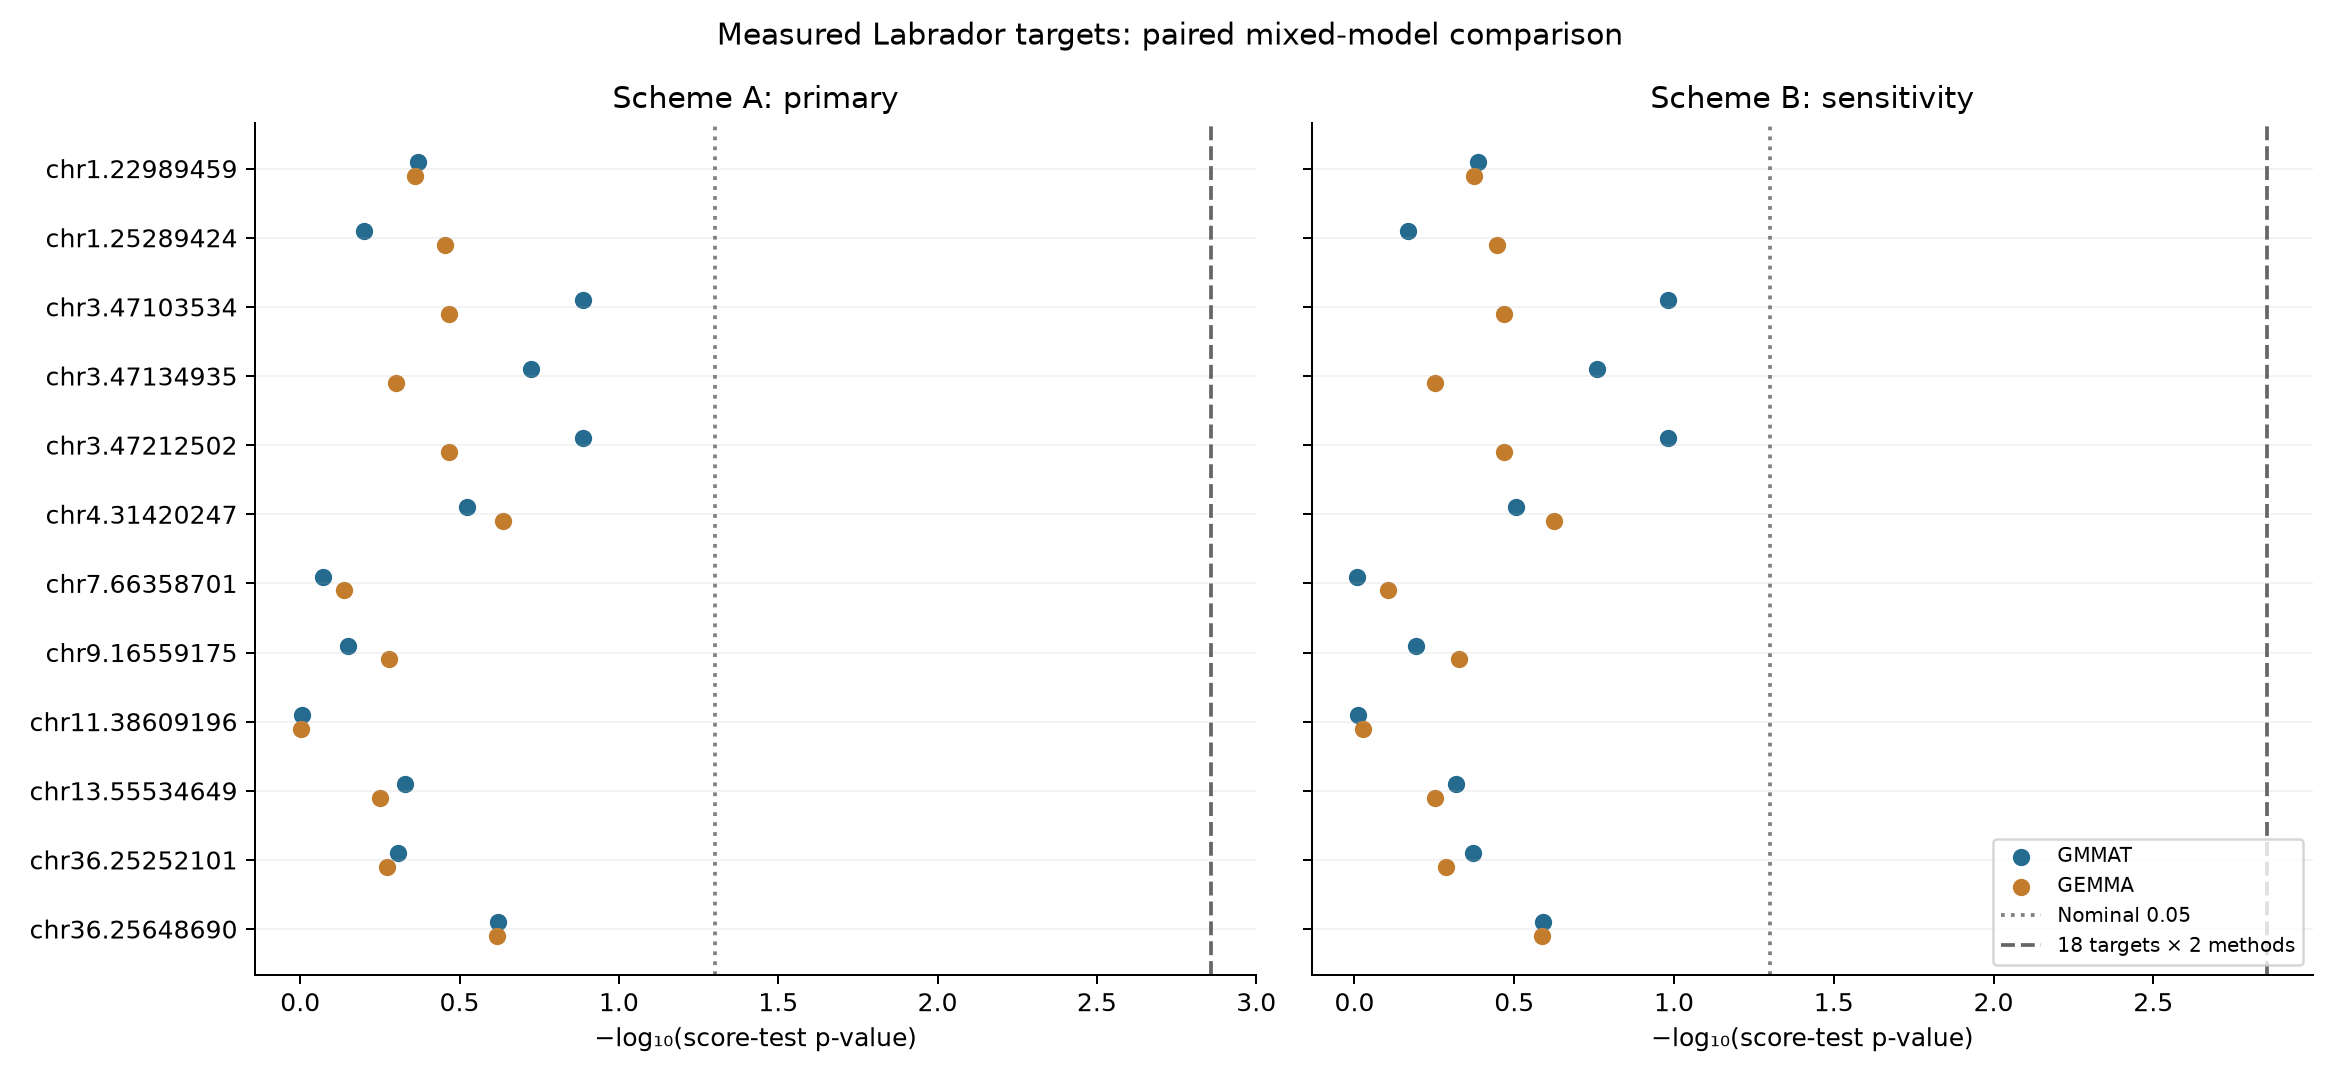

In [7]:
# Summarize the saved paired-model results and display their score-test comparison.
# This reads the completed fits rather than selecting the method with the smaller probability.

figure_folder = study_root / "results/private/version2/06_2013tsa_lr_replication"
# run_script(study_root, "summarize_replication.py", "--run-dir", model_folder,
#            "--results-dir", figure_folder)
summary = read_json(figure_folder / "summary.private.json")
from IPython.display import Image
display(Image(filename=str(figure_folder / "paired_score_tests.png")))

In [8]:
# Display primary-cohort score tests, sample sizes and logistic effect-fit status side by side.
# Keeping fit warnings visible prevents unstable effects from appearing as reliable estimates.

with (figure_folder / "paired_models.private.tsv").open(encoding="utf-8", newline="") as handle:
    paired_results = list(csv.DictReader(handle, delimiter="\t"))
lines = ['| CanFam3.1 Target | GMMAT Score P | GEMMA Score P | Dogs | GMMAT Effect Fit |',
         '| :---: | :---: | :---: | :---: | :---: |']
primary_results = [r for r in paired_results if r["scenario"] == "success-vs-behelim"]
for i in range(0, len(primary_results), 2):
    logistic, linear = primary_results[i:i+2]
    fit = "Converged" if logistic["effect_fit_converged"] == "True" else "Unstable; effect omitted"
    lines.append(f"| {logistic['historical_target']} | {float(logistic['score_p']):.4g} | "
                 f"{float(linear['score_p']):.4g} | {logistic['dogs']} | {fit} |")
display(Markdown("\n".join(lines)))

| CanFam3.1 Target | GMMAT Score P | GEMMA Score P | Dogs | GMMAT Effect Fit |
| :---: | :---: | :---: | :---: | :---: |
| chr1.22989459 | 0.4269 | 0.4361 | 46 | Converged |
| chr1.25289424 | 0.6296 | 0.3508 | 46 | Converged |
| chr3.47103534 | 0.1295 | 0.3425 | 46 | Converged |
| chr3.47134935 | 0.189 | 0.5011 | 46 | Converged |
| chr3.47212502 | 0.1295 | 0.3425 | 46 | Converged |
| chr4.31420247 | 0.2994 | 0.2305 | 45 | Unstable; effect omitted |
| chr7.66358701 | 0.8482 | 0.7291 | 46 | Converged |
| chr9.16559175 | 0.7061 | 0.5256 | 46 | Converged |
| chr11.38609196 | 0.9903 | 0.9972 | 46 | Converged |
| chr13.55534649 | 0.4682 | 0.5632 | 46 | Unstable; effect omitted |
| chr36.25252101 | 0.492 | 0.534 | 46 | Converged |
| chr36.25648690 | 0.2399 | 0.2411 | 46 | Unstable; effect omitted |

### Interpretation
- No score-test probability is below 0.05 in either scheme.
- Scheme A minima are 0.130 for GMMAT and 0.231 for GEMMA.
- Seven cases provide limited evidence about absence of an effect.
- All 24 GMMAT null models converge, but effect fits fail at three targets per scheme.
- GEMMA alternative variance ratios reach their upper boundary in every comparison.

### Effect Estimates
- GMMAT coefficients are log odds per counted allele; GEMMA coefficients are on the 0/1 outcome scale.
- ALT labels and large unstable coefficients do not identify historical risk effects.
- Failed fits are excluded from effect interpretation.

### (Simulation) Null Simulations
- The initial screen uses 100 simulations per target and scheme with no target effect and exactly seven cases.
- It compares nominal false-positive rates after refitting and counts failed fits separately.
- Of 2,400 simulated datasets, 2,360 yield valid paired tests and 40 fail.
- Wide intervals and variable rejection rates do not establish calibration, especially near the corrected threshold.

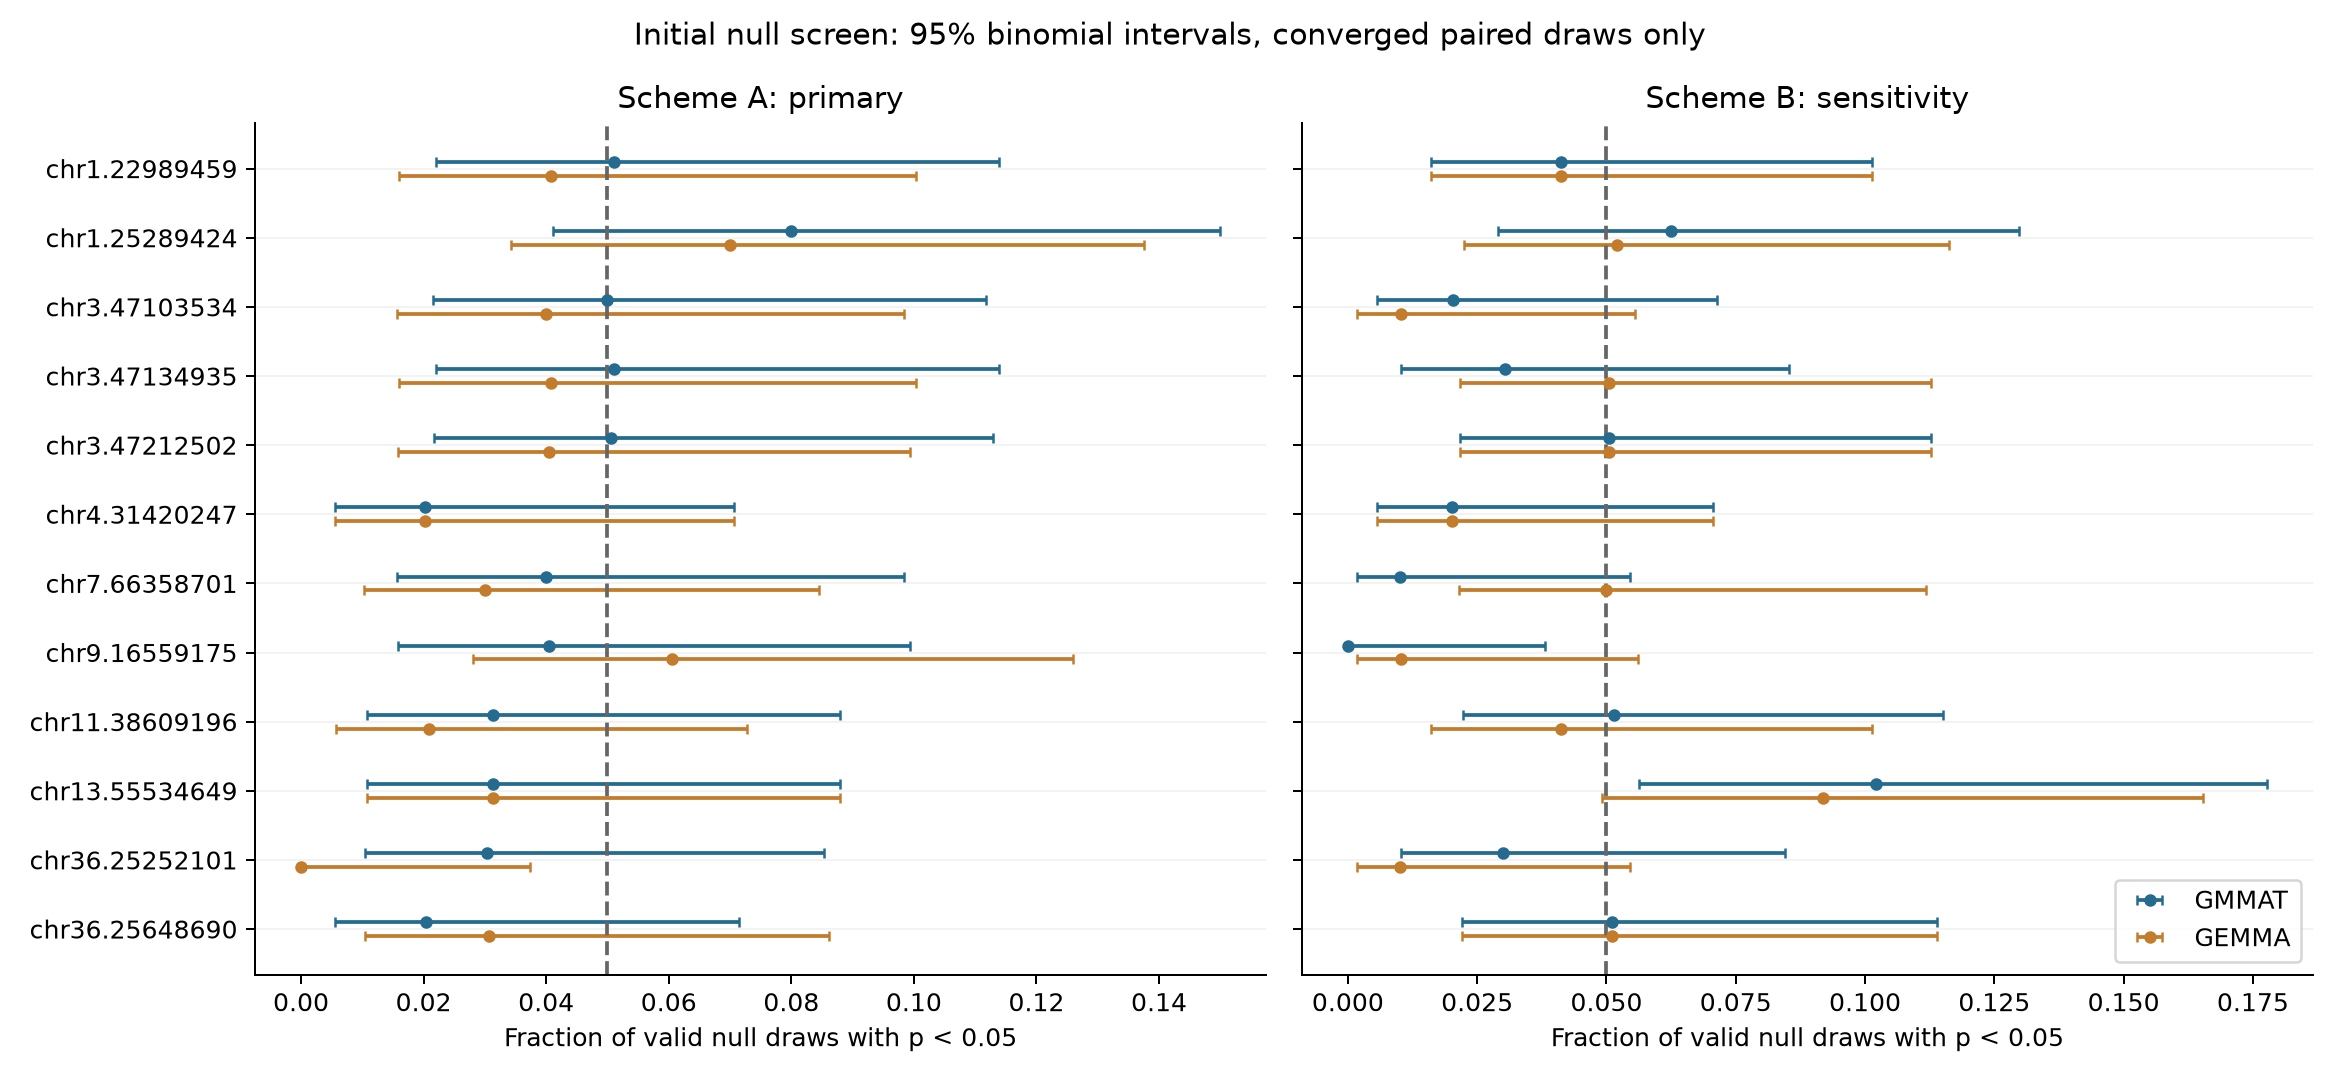

| CanFam3.1 Target | Valid Paired Draws | Failed Draws | GMMAT P < 0.05 | GEMMA P < 0.05 |
| :---: | :---: | :---: | :---: | :---: |
| chr1.22989459 | 98 | 2 | 5.1% | 4.1% |
| chr1.25289424 | 100 | 0 | 8.0% | 7.0% |
| chr3.47103534 | 100 | 0 | 5.0% | 4.0% |
| chr3.47134935 | 98 | 2 | 5.1% | 4.1% |
| chr3.47212502 | 99 | 1 | 5.1% | 4.0% |
| chr4.31420247 | 99 | 1 | 2.0% | 2.0% |
| chr7.66358701 | 100 | 0 | 4.0% | 3.0% |
| chr9.16559175 | 99 | 1 | 4.0% | 6.1% |
| chr11.38609196 | 96 | 4 | 3.1% | 2.1% |
| chr13.55534649 | 96 | 4 | 3.1% | 3.1% |
| chr36.25252101 | 99 | 1 | 3.0% | 0.0% |
| chr36.25648690 | 98 | 2 | 2.0% | 3.1% |

All comparisons: 2360 valid paired draws and 40 failed draws.


In [9]:
# Display the saved null-simulation screen and count valid and failed paired tests.
# Both are needed to interpret apparent false-positive rates in the small case group.

display(Image(filename=str(figure_folder / "null_screen.png")))
lines = ['| CanFam3.1 Target | Valid Paired Draws | Failed Draws | GMMAT P < 0.05 | GEMMA P < 0.05 |',
         "| :---: | :---: | :---: | :---: | :---: |"]
for i in range(0, len(primary_results), 2):
    logistic, linear = primary_results[i:i+2]
    lines.append(f"| {logistic['historical_target']} | {logistic['null_replicates_valid']} | "
                 f"{logistic['null_replicates_failed']} | {float(logistic['null_rate_below_05']):.1%} | "
                 f"{float(linear['null_rate_below_05']):.1%} |")
display(Markdown("\n".join(lines)))
print("All comparisons:", summary["paired_null_draws_valid"], "valid paired draws and",
      summary["paired_null_draws_failed"], "failed draws.")

### What Remains Unresolved?
- Directional replication needs matched historical alleles and contrasts
- Genotype-specific effects are not automatically per-allele effects.
- Further small-sample assessment remains necessary.
- [Replication methods](../docs/methods/06%20Targeted%20Labrador%20replication.md) describe the models and checks.

### (Simulation) Power and False-Positive Rates
- Power measures detection with a specified effect.
- Null simulations measure rejection without a direct target effect.
- Both workflows test the same simulated outcomes.
- The pilot contains 1,200 outcomes across three low-frequency contexts, odds ratios 1, 1.5, 2, 3 and 5, and zero/fitted background variance.
- It preserves genotypes, sex, relationship matrices and fixed case counts.
- It retains 15 failed GMMAT tests and 1,141 GEMMA boundary fits, with uncertainty and failure bounds.
- This is a framework check, not final study-wide power or extreme-tail validation.
- Larger simulations are separate calculations.
- [Power methods](../docs/methods/06%20Power%20and%20simulation.md) give the assumptions.
- *power_framework.py*
- *verify_power_framework.py*
- *plot_study_extensions.py*

Simulated outcomes: 1200
Failed tests: {'GMMAT_score': 15, 'GEMMA_wald': 0, 'GEMMA_lrt': 0, 'GEMMA_score': 0}
GEMMA boundary draws: 1141


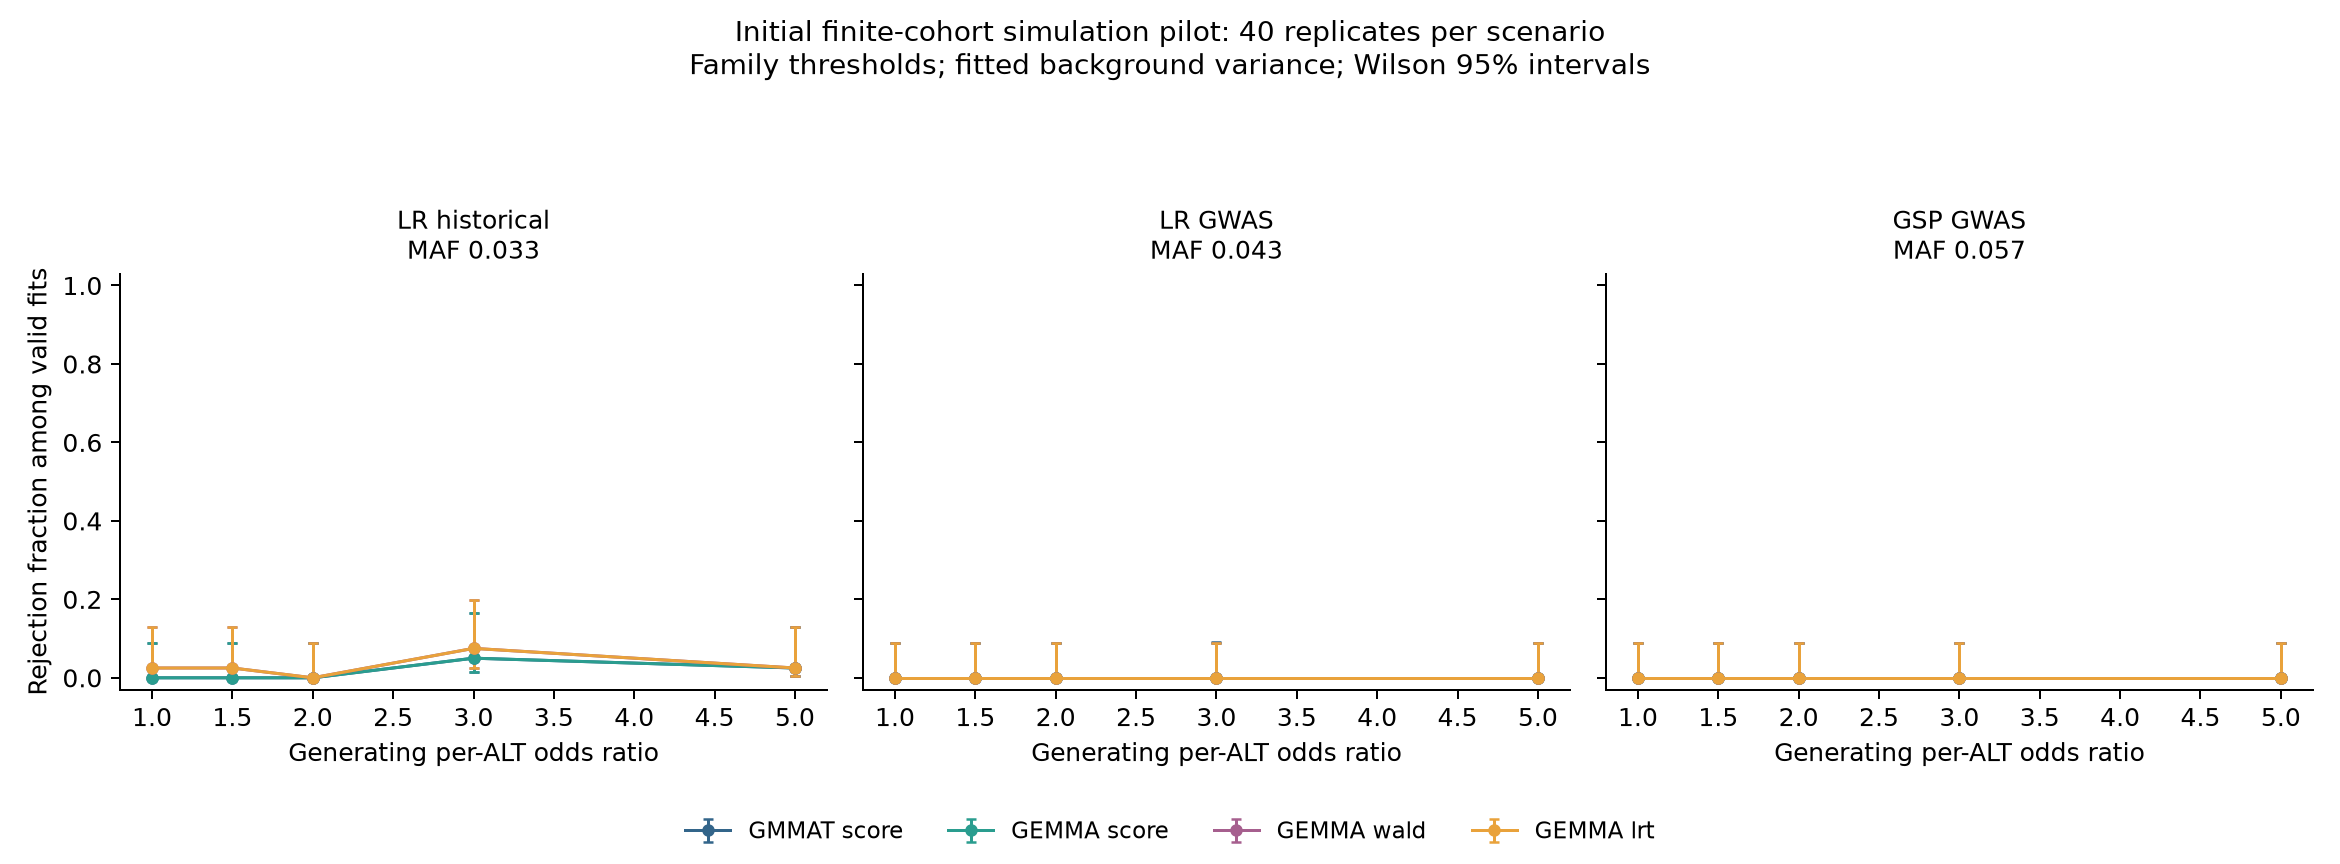

Null-scenario rows retained: 24 with intervals and failure bounds


In [10]:
# Read the completed power pilot and its independent checks, then display the summary.
# Retain failed tests, boundary fits and null-scenario rows so simulation limitations remain visible.

# run_script(study_root, "power_framework.py", linux=True)  # verifies the completed pilot
# run_script(study_root, "verify_power_framework.py", linux=True)
from extension_support import rows as extension_rows
from IPython.display import Image, display
power_folder = study_root / read_json(study_root / "config/power.json")["output_directory"]
power_summary = read_json(power_folder / "summary.private.json")
power_checks = read_json(power_folder / "verification.private.json")
assert power_checks["status"] == "passed"
print("Simulated outcomes:", power_summary["total_simulated_outcomes"])
print("Failed tests:", power_checks["failed_tests_by_method"])
print("GEMMA boundary draws:", power_checks["GEMMA_boundary_draws"])
# run_script(study_root, "plot_study_extensions.py", "--stage", "power")
if (power_folder / "pilot_power.png").exists():
    display(Image(filename=str(power_folder / "pilot_power.png")))
power_rates = extension_rows(power_folder / "rates.private.tsv")
null_rates = [r for r in power_rates if float(r["generating_OR"]) == 1 and r["threshold_label"] == "nominal"]
print("Null-scenario rows retained:", len(null_rates), "with intervals and failure bounds")

### (Simulation) Full Power Simulation
- *power_framework.py*

In [11]:
# Optionally launch the larger simulation grid in a separate output folder.
# The full-grid command is a commented example because it is a substantial calculation.

# Full runs are explicit and require a new output folder. The current full
# grid contains 540,000 simulated datasets at 1,000 replicates per cell.
#     full_output = study_root / "results/private/version2/06_power/full-20261013"
#     run_script(study_root, "power_framework.py", "--profile", "full", "--output", full_output, linux=True)